# NeoStay — what is in the dataset today

This notebook describes **every dataset the project actually holds**, measures what those data can and
cannot support, and writes the figures used by `docs/NeoStay-Data-Analysis.pdf`.

Two rules govern it:

1. **Only real data.** Every number below is read from a file in `datasets/`. Nothing is generated,
   simulated or imputed, and the project no longer contains synthetic data of any kind.
2. **No patient-level records.** The outcome files are aggregated statistics — counts, medians and
   quartiles per group. No row describes an individual infant.

Run order is top to bottom; the notebook writes PNG figures into `docs/analysis/figures/`.

## 1 · Setup

In [1]:
import csv
import hashlib
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "datasets").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "backend"))

FIG_DIR = ROOT / "docs" / "analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# NeoStay palette, so the figures match the application and the documents.
TEAL, GOLD, ROSE, GREEN = "#0e8a8f", "#c9a24b", "#d5637a", "#10998a"
INK, MUTED, GRID = "#122b36", "#74909c", "#e3ebef"
mpl.rcParams.update({
    "figure.dpi": 140, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "semibold",
    "axes.labelcolor": INK, "axes.edgecolor": GRID, "axes.labelsize": 9,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
print("repository:", ROOT)
print("figures   :", FIG_DIR.relative_to(ROOT))

repository: /Users/razakabdul/Documents/GitHub/patient-nurse-schedule
figures   : docs/analysis/figures


## 2 · Inventory — every file the project holds

Three folders, and nothing else. The table states what each file is, and whether the application reads it.

In [2]:
PARSED_BY = {
    "losdata/Center-1_2016-to-2026__All VLBW Infants_by-Birth Wgt 10 Levels-survival.csv":
        "backend/app/data_loader.py",
    "losdata/Center-1_2016-to-2026__Total Length Of Stay_All VLBW Infants_by-Birth Wgt 10 Levels.csv":
        "backend/app/data_loader.py",
    "losdata/Center-1_2016-to-2026__Total Length Of Stay_All VLBW Infants_by-GA Week.csv":
        "backend/app/data_loader.py",
    "nurse-skills/page_1_abrazo_arrowhead_neonatal_acuity_tool.csv": "backend/app/acuity_tool.py",
    "nurse-skills/page_2_nursing_levels_of_care_hyperbilirubinemia.csv": "backend/app/acuity_tool.py",
    "nurse-skills/page_3_nursing_levels_of_care.csv": "backend/app/acuity_tool.py",
}

rows = []
for path in sorted((ROOT / "datasets").rglob("*")):
    if path.is_dir() or path.name == ".DS_Store":
        continue
    rel = path.relative_to(ROOT / "datasets").as_posix()
    rows.append({
        "file": rel,
        "kind": path.suffix.lstrip(".").upper(),
        "KB": round(path.stat().st_size / 1024, 1),
        "read by": PARSED_BY.get(rel, "— not read by the application"),
    })

inventory = pd.DataFrame(rows)
print(f"{len(inventory)} files, {inventory['KB'].sum() / 1024:.1f} MB in total\n")
inventory

18 files, 11.8 MB in total



,file,kind,KB,read by
0,losdata/Center-1_2016-to-2026__All VLBW Infant...,CSV,2.3,backend/app/data_loader.py
1,losdata/Center-1_2016-to-2026__All VLBW Infant...,PDF,208.9,— not read by the application
2,losdata/Center-1_2016-to-2026__All VLBW Infant...,PNG,63.7,— not read by the application
3,losdata/Center-1_2016-to-2026__All VLBW Infant...,CSV,1.0,— not read by the application
4,losdata/Center-1_2016-to-2026__All VLBW Infant...,PDF,73.8,— not read by the application
5,losdata/Center-1_2016-to-2026__All VLBW Infant...,PNG,43.2,— not read by the application
6,losdata/Center-1_2016-to-2026__Total Length Of...,CSV,0.7,backend/app/data_loader.py
7,losdata/Center-1_2016-to-2026__Total Length Of...,PDF,36.1,— not read by the application
8,losdata/Center-1_2016-to-2026__Total Length Of...,PNG,40.7,— not read by the application
9,losdata/Center-1_2016-to-2026__Total Length Of...,CSV,1.1,backend/app/data_loader.py


Three things follow from the inventory:

* The **source of truth is small**: four aggregated CSV tables of outcomes and three transcribed CSV tables
  of the acuity instrument. Everything the application shows is computed from those seven files.
* The **PNG and PDF files beside each outcome CSV are the centre's own charts** of the same numbers. They are
  kept for provenance and are never parsed.
* Two **policy documents** (`nurse-poicies/`) are held but not yet used in code: the acuity tool as a Word
  document, and the charge nurse's daily task list. The second is the only description the project has of how
  a shift is actually run, and it names the local artefacts a future data request should ask for.

In [3]:
import re
import zipfile

def docx_text(path: Path) -> str:
    with zipfile.ZipFile(path) as archive:
        xml = archive.read("word/document.xml").decode("utf-8")
    xml = xml.replace("</w:p>", "\n")
    text = re.sub(r"<[^>]+>", "", xml)
    return re.sub(r"\n{2,}", "\n", text).strip()

tasks = docx_text(ROOT / "datasets/nurse-poicies/NICU_Charge_Nurse_Daily_Task_List.docx")
artefacts = ["staffing matrix", "Acuity Tracker", "Denominator sheet", "handoff report",
             "assignments", "census", "Vascular Access Tracking"]
print("Local artefacts named in the charge nurse task list:")
for name in artefacts:
    hit = re.search(rf".{{0,60}}{re.escape(name)}.{{0,60}}", tasks, re.I)
    if hit:
        print(f"  • {name}: ...{hit.group(0).strip()}...")

Local artefacts named in the charge nurse task list:
  • staffing matrix: ...Make assignments utilizing the staffing matrix guides, assign code team, assign EOC tasks to staff...
  • Acuity Tracker: ...Fill out Monthly Acuity Tracker...
  • Denominator sheet: ...Complete NICU Denominator sheet...
  • handoff report: ...Receive handoff report from the off-going charge nurse, including a review of pati...
  • assignments: ...m the off-going charge nurse, including a review of patient assignments, the L&amp;D board, and any urgent issues or significant ch...
  • census: ...hift staffing needs, write down first admit dates/float/low census (if needed)...
  • Vascular Access Tracking: ...Verify Vascular Access Tracking has been completed...


## 3 · Reading the outcome tables

Each outcome CSV is a *wide* table: the first row names the groups (birth-weight bands, or gestational-age
weeks), the second row repeats `N / Median / Q1 / Q3` beneath every group, and each later row is one measure.
The parser below turns that shape into tidy rows, and is deliberately independent of the application's own
loader so that the two can be compared.

In [4]:
LOS_DIR = ROOT / "datasets" / "losdata"

def read_wide(path: Path) -> pd.DataFrame:
    """Return one tidy row per (measure, group): N, median, Q1, Q3."""
    rows = list(csv.reader(path.open(encoding="utf-8-sig")))
    header, sub = rows[0], rows[1]
    groups = [(start, header[start + 1]) for start in range(1, len(sub), 4)
              if start + 1 < len(header) and header[start + 1]]
    out = []
    for row in rows[2:]:
        if not row or not row[0]:
            continue
        for start, label in groups:
            cell = (row[start:start + 4] + ["", "", "", ""])[:4]
            number = lambda v: float(v) if v not in ("", None) else np.nan
            out.append({
                "source": path.name, "measure": row[0], "group": label,
                "n": number(cell[0]), "median": number(cell[1]),
                "q1": number(cell[2]), "q3": number(cell[3]),
            })
    frame = pd.DataFrame(out)
    frame["n"] = frame["n"].astype("Int64")
    return frame

tidy = pd.concat([read_wide(p) for p in sorted(LOS_DIR.glob("*.csv"))], ignore_index=True)
print("tidy rows:", len(tidy))
print("measures  :")
for measure, count in tidy.groupby("measure", sort=False).size().items():
    print(f"  {count:3d}  {measure}")
tidy.head()

tidy rows: 127
measures  :
   12  Initial Length of Stay (By Disposition) - Home
   12  Initial Length of Stay (By Disposition) - Transfer
   12  Initial Length of Stay (By Disposition) - Died
   12  Initial Length of Stay (By Disposition) - All
   24  Predicted Length of Stay
   55  Total Length Of Stay


,source,measure,group,n,median,q1,q3
0,Center-1_2016-to-2026__All VLBW Infants_by-Bir...,Initial Length of Stay (By Disposition) - Home,< 501 g,15,138.0,115.50,213.50
1,Center-1_2016-to-2026__All VLBW Infants_by-Bir...,Initial Length of Stay (By Disposition) - Home,501-600 g,25,122.0,101.00,152.00
2,Center-1_2016-to-2026__All VLBW Infants_by-Bir...,Initial Length of Stay (By Disposition) - Home,601-700 g,34,112.5,102.75,128.00
3,Center-1_2016-to-2026__All VLBW Infants_by-Bir...,Initial Length of Stay (By Disposition) - Home,701-800 g,44,103.0,90.50,120.25
4,Center-1_2016-to-2026__All VLBW Infants_by-Bir...,Initial Length of Stay (By Disposition) - Home,801-900 g,49,87.0,74.00,100.00


In [5]:
# Cross-check the independent parse against the application's own loader.
from app.data_loader import DATASET, GA_BINS, WEIGHT_BINS  # noqa: E402

mismatches = []
for table, measure_key in (("los_by_weight", "Total Length Of Stay"),
                           ("los_by_ga", "Total Length Of Stay"),
                           ("survival_by_weight", "Initial Length of Stay (By Disposition) - Died")):
    loaded = getattr(DATASET, table)[measure_key]
    bins = GA_BINS if table.endswith("ga") else WEIGHT_BINS
    for b in bins:
        mine = tidy[(tidy["measure"] == measure_key) & (tidy["group"] == b.label)]
        mine = mine.sort_values("source").iloc[0]
        theirs = loaded[b.label]
        if (int(mine["n"]) != theirs.n) or (float(mine["median"]) != theirs.median):
            mismatches.append((table, b.label, mine["n"], theirs.n))

print("rows compared against backend/app/data_loader.py:",
      len(WEIGHT_BINS) * 2 + len(GA_BINS))
print("mismatches:", mismatches or "none — the notebook and the application read the same numbers")

rows compared against backend/app/data_loader.py: 40
mismatches: none — the notebook and the application read the same numbers


## 4 · Completeness and internal consistency

Before any analysis: do the tables agree with themselves? Four checks — every band present, quartiles ordered,
band counts summing to the `All` column, and the disposition rows summing to their own total.

In [6]:
weight_labels = [b.label for b in WEIGHT_BINS]
ga_labels = [b.label for b in GA_BINS]

checks = []

# (a) every expected group present in every measure
for measure, frame in tidy.groupby("measure"):
    for source, part in frame.groupby("source"):
        expected = ga_labels if "GA Week" in source else weight_labels
        missing = [label for label in expected if label not in set(part["group"])]
        checks.append({"check": "all groups present", "measure": measure[:46],
                       "detail": source[-28:], "result": "ok" if not missing else f"missing {missing}"})

# (b) quartile ordering
bad_order = tidy.dropna(subset=["q1", "median", "q3"])
bad_order = bad_order[~((bad_order["q1"] <= bad_order["median"]) & (bad_order["median"] <= bad_order["q3"]))]
checks.append({"check": "Q1 <= median <= Q3", "measure": "every row", "detail": f"{len(tidy)} rows",
               "result": "ok" if bad_order.empty else f"{len(bad_order)} violations"})

# (c) band counts reconcile with the All column
for (measure, source), frame in tidy.groupby(["measure", "source"]):
    banded = frame[frame["group"] != "All"]["n"].sum()
    total = frame[frame["group"] == "All"]["n"]
    if total.empty:
        continue
    total = int(total.iloc[0])
    checks.append({"check": "bands sum to All", "measure": measure[:46], "detail": source[-28:],
                   "result": "ok" if banded == total else f"bands {banded} vs All {total}"})

consistency = pd.DataFrame(checks).drop_duplicates()
consistency

,check,measure,detail,result
0,all groups present,Initial Length of Stay (By Disposition) - All,h Wgt 10 Levels-survival.csv,ok
1,all groups present,Initial Length of Stay (By Disposition) - Died,h Wgt 10 Levels-survival.csv,ok
2,all groups present,Initial Length of Stay (By Disposition) - Home,h Wgt 10 Levels-survival.csv,ok
3,all groups present,Initial Length of Stay (By Disposition) - Tran,h Wgt 10 Levels-survival.csv,ok
4,all groups present,Predicted Length of Stay,h Wgt 10 Levels-survival.csv,ok
5,all groups present,Predicted Length of Stay,s_by-Birth Wgt 10 Levels.csv,ok
6,all groups present,Total Length Of Stay,h Wgt 10 Levels-survival.csv,ok
7,all groups present,Total Length Of Stay,s_by-Birth Wgt 10 Levels.csv,ok
9,all groups present,Total Length Of Stay,VLBW Infants_by-GA Week.csv,ok
10,Q1 <= median <= Q3,every row,127 rows,ok


In [7]:
# (d) do the three disposition rows account for every admission?
surv = tidy[tidy["source"].str.contains("survival")]
alls = surv[surv["group"] == "All"].set_index("measure")["n"]
home, transfer, died = (int(alls[f"Initial Length of Stay (By Disposition) - {k}"])
                        for k in ("Home", "Transfer", "Died"))
disposition_all = int(alls["Initial Length of Stay (By Disposition) - All"])
total_los_n = int(alls["Total Length Of Stay"])
predicted_n = int(alls["Predicted Length of Stay"])

print(f"home {home} + transfer {transfer} + died {died} = {home + transfer + died}")
print(f"disposition 'All' row                        = {disposition_all}"
      f"   → {disposition_all - (home + transfer + died)} admissions not attributed to an outcome")
print(f"infants with a recorded Total Length Of Stay = {total_los_n}"
      f"   → {disposition_all - total_los_n} fewer than the disposition total")
print(f"infants with a Predicted Length of Stay      = {predicted_n}"
      f"  → {disposition_all - predicted_n} fewer than the disposition total")

home 553 + transfer 73 + died 83 = 709
disposition 'All' row                        = 712   → 3 admissions not attributed to an outcome
infants with a recorded Total Length Of Stay = 708   → 4 fewer than the disposition total
infants with a Predicted Length of Stay      = 618  → 94 fewer than the disposition total


These four gaps are **the first real finding of the analysis**. The tables are internally ordered and complete
at band level, but the denominators differ between measures: a handful of admissions carry no discharge
outcome, a few carry no total stay, and the predicted-stay measure covers a visibly smaller group. With
aggregated data there is no way to tell which infants are missing or why. Every rate computed below therefore
states the denominator it used.

## 5 · Length of stay by birth weight

,n,median,q1,q3,IQR
group,,,,,
< 501 g,38,43.5,10.00,149.00,139.00
501-600 g,44,119.5,67.00,145.25,78.25
601-700 g,55,112.0,99.00,135.50,36.50
701-800 g,64,100.0,77.25,124.75,47.50
801-900 g,62,88.0,63.00,103.00,40.00
901-1000 g,63,73.0,57.00,94.00,37.00
1001-1100 g,65,63.0,50.00,74.00,24.00
1101-1200 g,56,61.0,48.75,73.00,24.25
1201-1300 g,63,52.0,35.50,64.50,29.00


findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


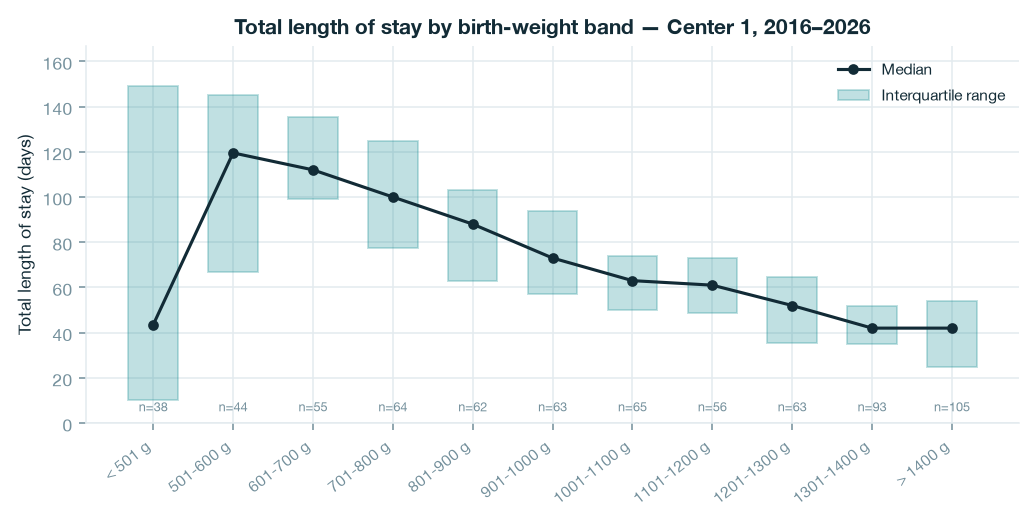

In [8]:
los_w = (tidy[(tidy["measure"] == "Total Length Of Stay")
              & (tidy["source"].str.contains("Birth Wgt"))
              & (tidy["group"] != "All")]
         .drop_duplicates(subset="group")
         .set_index("group").loc[weight_labels])
los_w["IQR"] = los_w["q3"] - los_w["q1"]
display(los_w[["n", "median", "q1", "q3", "IQR"]])

fig, ax = plt.subplots(figsize=(8.6, 3.5))
x = np.arange(len(los_w))
ax.bar(x, los_w["q3"] - los_w["q1"], bottom=los_w["q1"], width=0.62,
       color=TEAL, alpha=0.26, edgecolor=TEAL, linewidth=1.0, label="Interquartile range")
ax.plot(x, los_w["median"], "-o", color=INK, markersize=4.5, linewidth=1.6, label="Median")
ax.set_ylim(0, float(los_w["q3"].max()) * 1.12)
for i, n in enumerate(los_w["n"]):
    ax.annotate(f"n={n}", (i, 4), ha="center", va="bottom", fontsize=6.6, color=MUTED)
ax.set_xticks(x); ax.set_xticklabels(los_w.index, rotation=38, ha="right", fontsize=8)
ax.set_ylabel("Total length of stay (days)")
ax.set_title("Total length of stay by birth-weight band — Center 1, 2016–2026")
ax.legend(frameon=False, fontsize=8, loc="upper right")
fig.savefig(FIG_DIR / "los_by_weight.png")
plt.show()

The gradient is the finding the application rests on: between the 501–600 g band and the heaviest band the
median stay falls from about four months to about six weeks. The `< 501 g` band breaks the pattern — its
median is **lower** than the band above it, with an interquartile range several times wider. Section 6 shows
why: half of those admissions did not survive, and a death usually ends the stay early.

## 6 · Discharge outcome by birth weight

,Home,Transfer,Died,All,unattributed,Home %,Transfer %,Died %
group,,,,,,,,
< 501 g,15,3,20,39,1,38.5,7.7,51.3
501-600 g,25,8,11,45,1,55.6,17.8,24.4
601-700 g,34,13,8,55,0,61.8,23.6,14.5
701-800 g,44,11,9,64,0,68.8,17.2,14.1
801-900 g,49,6,7,62,0,79.0,9.7,11.3
901-1000 g,55,5,3,63,0,87.3,7.9,4.8
1001-1100 g,56,7,3,66,0,84.8,10.6,4.5
1101-1200 g,45,8,3,56,0,80.4,14.3,5.4
1201-1300 g,54,3,6,63,0,85.7,4.8,9.5


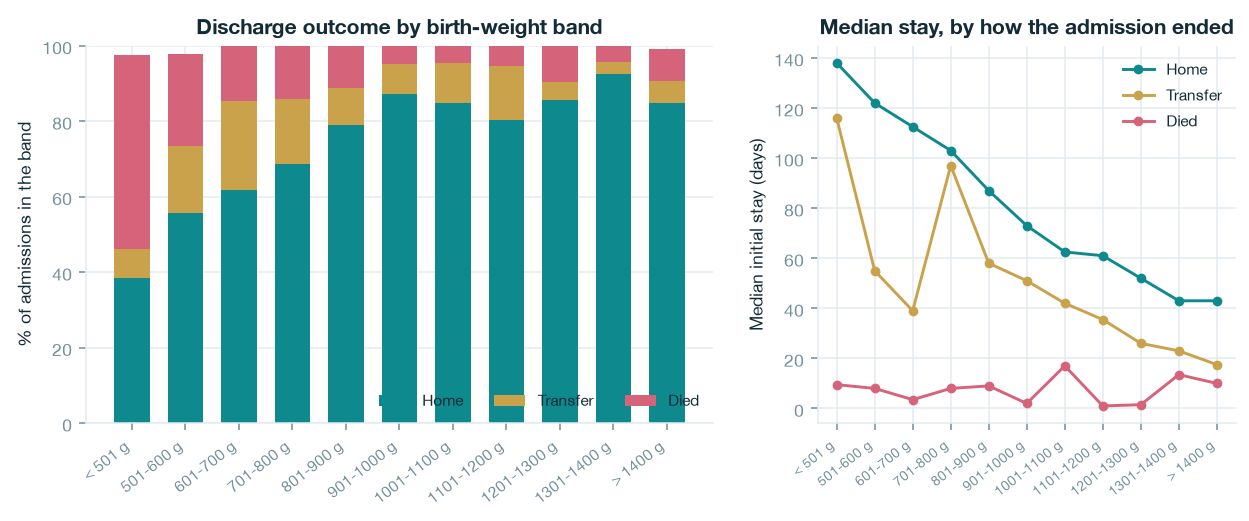

Cohort-wide: 77.7% home, 10.3% transferred, 11.7% died (denominator 712).


In [9]:
disp = (surv[surv["group"] != "All"]
        .pivot_table(index="group", columns="measure", values="n", aggfunc="first")
        .loc[weight_labels])
disp.columns = [c.replace("Initial Length of Stay (By Disposition) - ", "") for c in disp.columns]
outcome = disp[["Home", "Transfer", "Died", "All"]].astype(float)
outcome["unattributed"] = outcome["All"] - outcome[["Home", "Transfer", "Died"]].sum(axis=1)
share = outcome[["Home", "Transfer", "Died"]].div(outcome["All"], axis=0) * 100
display(pd.concat([outcome.astype("Int64"), share.add_suffix(" %").round(1)], axis=1))

fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.5), gridspec_kw={"width_ratios": [1.5, 1]})
x = np.arange(len(share))
bottom = np.zeros(len(share))
for column, colour in (("Home", TEAL), ("Transfer", GOLD), ("Died", ROSE)):
    axes[0].bar(x, share[column], bottom=bottom, width=0.66, color=colour, label=column)
    bottom += share[column].to_numpy()
axes[0].set_xticks(x); axes[0].set_xticklabels(share.index, rotation=38, ha="right", fontsize=8)
axes[0].set_ylabel("% of admissions in the band"); axes[0].set_ylim(0, 100)
axes[0].set_title("Discharge outcome by birth-weight band")
axes[0].legend(frameon=False, fontsize=8, ncol=3, loc="lower right")

median_by_outcome = (surv[surv["group"] != "All"]
                     .pivot_table(index="group", columns="measure", values="median", aggfunc="first")
                     .loc[weight_labels])
median_by_outcome.columns = [c.replace("Initial Length of Stay (By Disposition) - ", "")
                             for c in median_by_outcome.columns]
for column, colour in (("Home", TEAL), ("Transfer", GOLD), ("Died", ROSE)):
    axes[1].plot(x, median_by_outcome[column], "-o", color=colour, markersize=4, linewidth=1.5, label=column)
axes[1].set_xticks(x); axes[1].set_xticklabels(share.index, rotation=38, ha="right", fontsize=7)
axes[1].set_ylabel("Median initial stay (days)")
axes[1].set_title("Median stay, by how the admission ended")
axes[1].legend(frameon=False, fontsize=8)
fig.savefig(FIG_DIR / "disposition_by_weight.png")
plt.show()

print("Cohort-wide:", f"{home / disposition_all:.1%} home,",
      f"{transfer / disposition_all:.1%} transferred,",
      f"{died / disposition_all:.1%} died (denominator {disposition_all}).")

Two observations an outcome model must respect:

* **Mortality is concentrated in the smallest band** and falls steeply with weight, so length of stay and
  survival cannot be modelled independently of each other.
* **Each outcome has its own stay distribution.** Infants who died have a median stay of days; infants
  transferred leave earlier than those discharged home. A single "length of stay" figure averages three
  different processes — which is why the application reports the disposition mix beside every forecast.

## 7 · Length of stay by gestational age

group,< 22 Weeks,22 Weeks,23 Weeks,24 Weeks,25 Weeks,26 Weeks,27 Weeks,28 Weeks,29 Weeks,30 Weeks,31 Weeks,32 Weeks,33 Weeks,34 Weeks,35 Weeks,36 Weeks,37 Weeks,> 37 Weeks
n,4,22,40,55,81,53,62,101,98,74,41,33,22,13,1,4,2,2
median,1.0,128.0,121.0,111.0,102.0,89.0,73.5,64.0,52.5,48.0,36.0,31.0,29.0,22.0,25.0,16.5,26.0,24.5
q1,1.0,8.5,11.0,27.5,86.0,68.0,63.0,53.0,43.0,41.25,32.0,24.0,25.0,18.0,25.0,10.75,23.5,23.25
q3,32.5,164.25,157.25,124.0,122.0,99.0,95.0,76.0,61.0,54.0,43.0,46.0,52.5,38.0,25.0,21.25,28.5,25.75


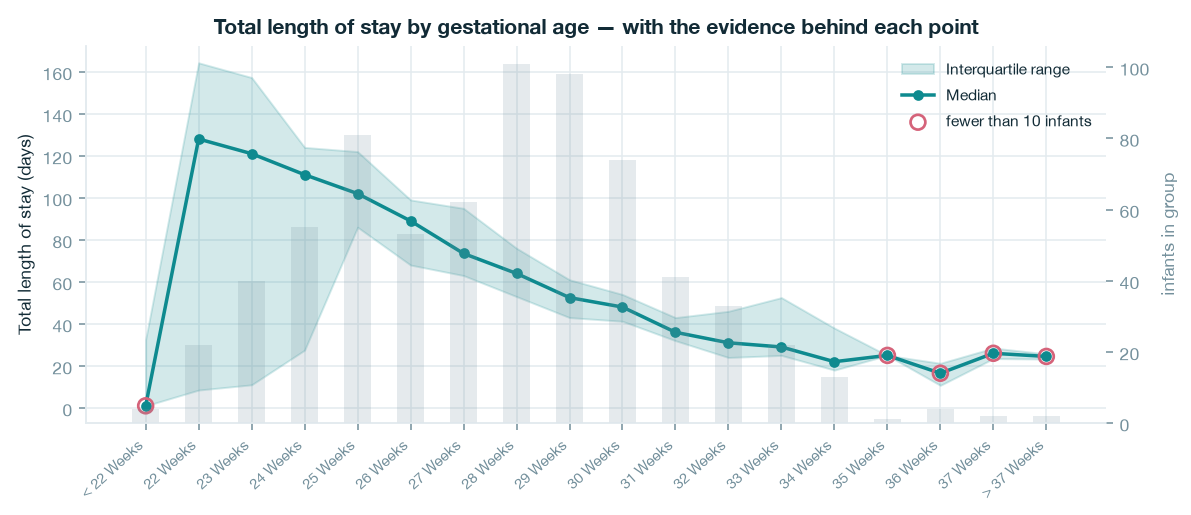

groups with fewer than 10 infants: < 22 Weeks (n=4), 35 Weeks (n=1), 36 Weeks (n=4), 37 Weeks (n=2), > 37 Weeks (n=2)


In [10]:
los_ga = (tidy[(tidy["measure"] == "Total Length Of Stay")
               & (tidy["source"].str.contains("GA Week"))
               & (tidy["group"] != "All")]
          .set_index("group").loc[ga_labels])
display(los_ga[["n", "median", "q1", "q3"]].T)

fig, ax = plt.subplots(figsize=(9.4, 3.5))
x = np.arange(len(los_ga))
ax.fill_between(x, los_ga["q1"], los_ga["q3"], color=TEAL, alpha=0.18, label="Interquartile range")
ax.plot(x, los_ga["median"], "-o", color=TEAL, markersize=4.5, linewidth=1.8, label="Median")
thin = los_ga["n"] < 10
ax.scatter(x[thin.to_numpy()], los_ga["median"][thin.to_numpy()], s=58, facecolors="none",
           edgecolors=ROSE, linewidths=1.4, label="fewer than 10 infants", zorder=5)
ax2 = ax.twinx()
ax2.bar(x, los_ga["n"].astype(float), width=0.5, color=MUTED, alpha=0.18)
ax2.set_ylabel("infants in group", color=MUTED); ax2.grid(False)
ax.set_xticks(x); ax.set_xticklabels(los_ga.index, rotation=42, ha="right", fontsize=7.6)
ax.set_ylabel("Total length of stay (days)")
ax.set_title("Total length of stay by gestational age — with the evidence behind each point")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG_DIR / "los_by_ga.png")
plt.show()

print("groups with fewer than 10 infants:",
      ", ".join(f"{g} (n={int(n)})" for g, n in los_ga["n"].items() if n < 10))

The gestational-age view carries the same message as the weight view, but its tails are thin: several groups
hold fewer than ten infants, and the `< 22 Weeks` group holds four. The application already refuses to present
such estimates as confident — its confidence grades are driven by exactly this count — and a fitted model
would have to pool these groups rather than estimate them separately.

## 8 · The predicted-stay measure already in the extract

,n (predicted),median (predicted),n (observed),median (observed),difference
group,,,,,
< 501 g,15,141.0,38,43.5,97.5
501-600 g,31,138.0,44,119.5,18.5
601-700 g,47,131.0,55,112.0,19.0
701-800 g,55,106.0,64,100.0,6.0
801-900 g,55,100.0,62,88.0,12.0
901-1000 g,60,86.5,63,73.0,13.5
1001-1100 g,62,75.5,65,63.0,12.5
1101-1200 g,53,67.0,56,61.0,6.0
1201-1300 g,56,58.0,63,52.0,6.0


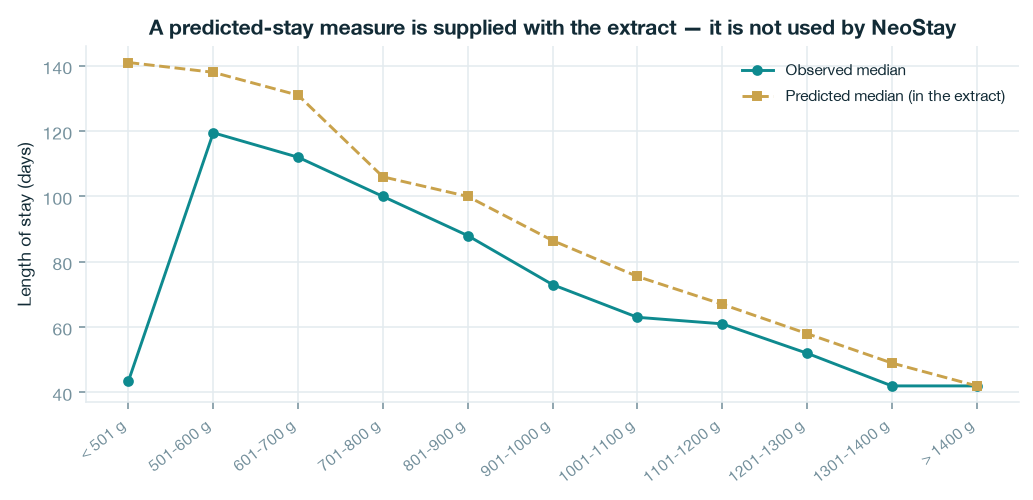

In [11]:
pred = (tidy[(tidy["measure"] == "Predicted Length of Stay") & (tidy["group"] != "All")]
        .drop_duplicates(subset="group").set_index("group").loc[weight_labels])
compare = pd.DataFrame({
    "n (predicted)": pred["n"], "median (predicted)": pred["median"],
    "n (observed)": los_w["n"], "median (observed)": los_w["median"],
})
compare["difference"] = compare["median (predicted)"] - compare["median (observed)"]
display(compare)

fig, ax = plt.subplots(figsize=(8.6, 3.3))
x = np.arange(len(compare))
ax.plot(x, compare["median (observed)"], "-o", color=TEAL, markersize=4.5, label="Observed median")
ax.plot(x, compare["median (predicted)"], "--s", color=GOLD, markersize=4, label="Predicted median (in the extract)")
ax.set_xticks(x); ax.set_xticklabels(compare.index, rotation=38, ha="right", fontsize=8)
ax.set_ylabel("Length of stay (days)")
ax.set_title("A predicted-stay measure is supplied with the extract — it is not used by NeoStay")
ax.legend(frameon=False, fontsize=8)
fig.savefig(FIG_DIR / "predicted_vs_observed.png")
plt.show()

The extract contains a **`Predicted Length of Stay`** measure alongside the observed one. Its method is not
documented in the files, it covers a smaller group than the disposition rows, and it sits above the observed
median in every band except the smallest. NeoStay does not read it: the application's own forecast is built
from the observed medians and quartiles. It is listed here because a reader of the raw files will find it, and
because asking the centre how it was produced is a cheap and worthwhile question.

## 9 · The acuity instrument as data

The second dataset is the unit's acuity policy, transcribed from a scanned document into three CSV tables and
parsed by `backend/app/acuity_tool.py`. The scan itself is never read by the program, and the handwritten
annotations on it are deliberately ignored.

In [12]:
from app.acuity_tool import CARE_LEVELS, FINDINGS, RATIO_COLUMNS, TOOL, classify  # noqa: E402

# The tool prints two "Continuing care" columns (1:3 and 1:3-4), so label each by its ratio.
COLUMN_LABEL = {c["key"]: f'{c["name"]} {c["ratio"]}' for c in RATIO_COLUMNS}

counts = []
for system in TOOL["systems"]:
    row = {"body system": system["system"]}
    for column in RATIO_COLUMNS:
        row[COLUMN_LABEL[column["key"]]] = len(system["items"][column["key"]])
    counts.append(row)
structure = pd.DataFrame(counts).set_index("body system")
structure["total"] = structure.sum(axis=1)
display(structure)

one_to_one = [f for f in FINDINGS.values() if f.get("one_to_one")]
grid_findings = sum(structure["total"])
print(f"{len(TOOL['systems'])} body systems · {grid_findings} findings in the grid ·"
      f" {len(RATIO_COLUMNS)} ratio columns · {len(FINDINGS)} selectable items in all"
      f" (grid findings + the footnoted 1:1 criterion + {sum(len(b['criteria']) for b in TOOL['levels_of_care'].values())} level-of-care criteria)")
print(f"{len(one_to_one)} findings carry the footnoted 1:1 rule:",
      ", ".join(f["label"][:44] for f in one_to_one))
for group, block in TOOL["levels_of_care"].items():
    levels = pd.Series([c["level"] for c in block["criteria"]]).value_counts().sort_index()
    print(f"levels of care · {group}: {len(block['criteria'])} criteria",
          "·", ", ".join(f"N{lvl}={n}" for lvl, n in levels.items()))

,Intensive care 1:2 or 1:1,Intermediate care 1:2–3,Continuing care 1:3,Continuing care 1:3–4,total
body system,,,,,
Weight/age,1,0,0,0,1
Respiratory,3,2,1,1,7
Cardiovascular,3,0,0,0,3
A/B/Ds,0,1,1,0,2
Nutrition,2,3,1,1,7
Neuro,3,1,1,1,6
Hyperbilirubinemia,2,1,1,1,5
Transfusions,1,1,0,0,2
Infection,1,1,1,0,3


11 body systems · 43 findings in the grid · 4 ratio columns · 108 selectable items in all (grid findings + the footnoted 1:1 criterion + 64 level-of-care criteria)
4 findings carry the footnoted 1:1 rule: Therapeutic Hypothermia/HIE, Multiple bili-lights and IV hydration and/or, Bedside surgical procedure, Hemodynamically unstable, needing nurse inte
levels of care · general: 45 criteria · N1=4, N2=13, N3=15, N4=13
levels of care · hyperbilirubinemia: 19 criteria · N1=6, N2=5, N3=4, N4=4


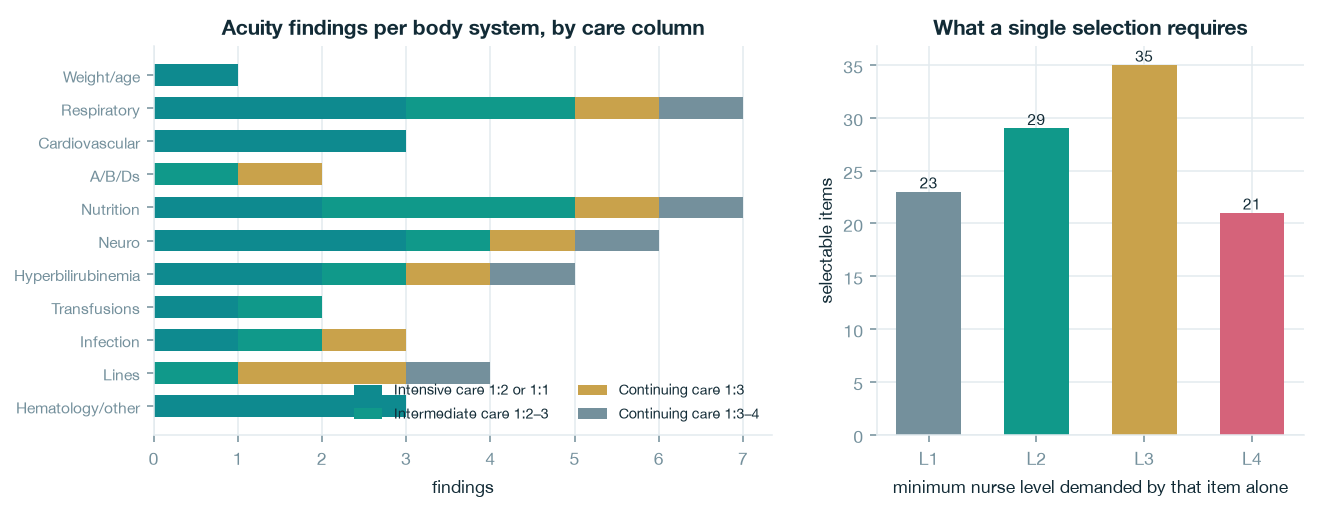

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.6), gridspec_kw={"width_ratios": [1.45, 1]})
colours = [TEAL, GREEN, GOLD, MUTED]
bottom = np.zeros(len(structure))
y = np.arange(len(structure))
for colour, column in zip(colours, RATIO_COLUMNS):
    label = COLUMN_LABEL[column["key"]]
    axes[0].barh(y, structure[label], left=bottom, color=colour, height=0.66, label=label)
    bottom += structure[label].to_numpy()
axes[0].set_yticks(y); axes[0].set_yticklabels(structure.index, fontsize=8)
axes[0].invert_yaxis(); axes[0].set_xlabel("findings"); axes[0].grid(axis="y", visible=False)
axes[0].set_title("Acuity findings per body system, by care column")
axes[0].legend(frameon=False, fontsize=7.4, ncol=2, loc="lower right")

required = pd.Series([classify([fid])["required_level"] for fid in FINDINGS]).value_counts().sort_index()
axes[1].bar([f"L{lvl}" for lvl in required.index], required.to_numpy(), width=0.6,
            color=[MUTED, GREEN, GOLD, ROSE][: len(required)])
for i, value in enumerate(required.to_numpy()):
    axes[1].annotate(str(value), (i, value), ha="center", va="bottom", fontsize=8, color=INK)
axes[1].set_ylabel("selectable items")
axes[1].set_xlabel("minimum nurse level demanded by that item alone")
axes[1].set_title("What a single selection requires")
fig.savefig(FIG_DIR / "acuity_structure.png")
plt.show()

The instrument is a **policy, not a sample**: it carries no counts and no outcomes, so nothing about its
accuracy can be measured from the files held today. What can be measured is its shape — where the clinical
detail sits (respiratory, nutrition and neurological findings dominate), how many findings on their own
demand an expert nurse, and how the levels of care distribute across N1–N4. Measuring whether the instrument
predicts actual nursing effort needs the shift-level record the project does not yet have.

## 10 · What these data support, and what they do not

In [14]:
support = pd.DataFrame([
    ("Expected stay for a group of similar infants", "Yes",
     "Medians and quartiles per weight band and per gestational week."),
    ("Chance of home / transfer / death for a group", "Yes",
     "Counts per band in the disposition table."),
    ("How confident an estimate is", "Yes",
     "N per band is published with every statistic."),
    ("Nurse:patient ratio and minimum competency per infant", "Yes",
     "The acuity instrument is complete and executable."),
    ("A stay prediction for an individual infant", "No",
     "Needs patient-level records (D1): no individual rows exist."),
    ("Effect of a specific clinical course on the stay", "No",
     "Needs daily course data (D2): weight and gestation are the only covariates held."),
    ("Joint effect of weight and gestation", "No",
     "The two tables describe the same cohort separately; no cross-tabulation is published."),
    ("Calibration, discrimination, external validation", "No",
     "Needs individual outcomes to compare predictions against."),
    ("Unit demand over time, seasonality, surges", "No",
     "Needs census and flow (D4): the files hold no dates."),
    ("Whether the acuity tool matches real nursing effort", "No",
     "Needs acuity per shift (D5) and actual staffing (D6)."),
    ("Rostering real named nurses", "No",
     "Needs the workforce list (D6): no staff data is held."),
], columns=["question", "answerable today", "why"])
display(support)
print(f"{(support['answerable today'] == 'Yes').sum()} of {len(support)} questions are answerable from the"
      " data held today; the rest wait on the extracts named in docs/NeoStay-Data-Requirements.pdf.")

,question,answerable today,why
0,Expected stay for a group of similar infants,Yes,Medians and quartiles per weight band and per ...
1,Chance of home / transfer / death for a group,Yes,Counts per band in the disposition table.
2,How confident an estimate is,Yes,N per band is published with every statistic.
3,Nurse:patient ratio and minimum competency per...,Yes,The acuity instrument is complete and executable.
4,A stay prediction for an individual infant,No,Needs patient-level records (D1): no individua...
5,Effect of a specific clinical course on the stay,No,Needs daily course data (D2): weight and gesta...
6,Joint effect of weight and gestation,No,The two tables describe the same cohort separa...
7,"Calibration, discrimination, external validation",No,Needs individual outcomes to compare predictio...
8,"Unit demand over time, seasonality, surges",No,Needs census and flow (D4): the files hold no ...
9,Whether the acuity tool matches real nursing e...,No,Needs acuity per shift (D5) and actual staffin...


4 of 11 questions are answerable from the data held today; the rest wait on the extracts named in docs/NeoStay-Data-Requirements.pdf.


## 11 · Figures written, and a checksum for every source file

The figures below are the ones embedded in `docs/NeoStay-Data-Analysis.pdf`. The checksums let any reader
confirm that the document and this notebook describe the same files.

In [15]:
for figure in sorted(FIG_DIR.glob("*.png")):
    print(f"  {figure.relative_to(ROOT)}  ({figure.stat().st_size / 1024:.0f} KB)")

print()
digests = []
for path in sorted((ROOT / "datasets").rglob("*.csv")):
    digest = hashlib.sha256(path.read_bytes()).hexdigest()[:16]
    digests.append({"file": path.relative_to(ROOT / "datasets").as_posix(), "sha256 (first 16)": digest})
pd.DataFrame(digests)

  docs/analysis/figures/acuity_structure.png  (93 KB)
  docs/analysis/figures/disposition_by_weight.png  (153 KB)
  docs/analysis/figures/los_by_ga.png  (160 KB)
  docs/analysis/figures/los_by_weight.png  (102 KB)
  docs/analysis/figures/predicted_vs_observed.png  (113 KB)



,file,sha256 (first 16)
0,losdata/Center-1_2016-to-2026__All VLBW Infant...,97d5a51acec67b35
1,losdata/Center-1_2016-to-2026__All VLBW Infant...,141c96e7e3907354
2,losdata/Center-1_2016-to-2026__Total Length Of...,6ac09402e2fb945d
3,losdata/Center-1_2016-to-2026__Total Length Of...,82f8087738108ce9
4,nurse-skills/page_1_abrazo_arrowhead_neonatal_...,e211ed1a6e185684
5,nurse-skills/page_2_nursing_levels_of_care_hyp...,38003385f2c5881b
6,nurse-skills/page_3_nursing_levels_of_care.csv,2842b260cdd92feb
